In [11]:
import tensorflow as tf
import numpy as np
import sys
import os

print("Python version:", sys.version)
print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("tf.keras path:", tf.keras.__file__)


Python version: 3.10.3 (tags/v3.10.3:a342a49, Mar 16 2022, 13:07:40) [MSC v.1929 64 bit (AMD64)]
TensorFlow version: 2.13.0
NumPy version: 1.24.3
tf.keras path: d:\predictions\venv\lib\site-packages\keras\api\_v2\keras\__init__.py


In [12]:
DATASET_PATH = "../dataset"   # same as your setup

print("Dataset exists:", os.path.exists(DATASET_PATH))
print("Classes:", os.listdir(DATASET_PATH))

for cls in os.listdir(DATASET_PATH):
    cls_path = os.path.join(DATASET_PATH, cls)
    print(cls, "images:", len(os.listdir(cls_path)))


Dataset exists: True
Classes: ['Healthy', 'Parkinson']
Healthy images: 1632
Parkinson images: 1632


In [13]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

print("Class order:", class_names)


Found 3264 files belonging to 2 classes.
Using 2612 files for training.
Found 3264 files belonging to 2 classes.
Using 652 files for validation.
Class order: ['Healthy', 'Parkinson']


In [14]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)


In [15]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])


In [16]:
from tensorflow.keras import models

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    data_augmentation,
    layers.Rescaling(1./255),

    layers.Conv2D(32, 3, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(256, 3, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(NUM_CLASSES, activation="softmax")
])

model.summary()


Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sequential_2 (Sequential)   (None, 224, 224, 3)       0         
                                                                 
 rescaling_1 (Rescaling)     (None, 224, 224, 3)       0         
                                                                 
 conv2d_4 (Conv2D)           (None, 222, 222, 32)      896       
                                                                 
 batch_normalization_4 (Bat  (None, 222, 222, 32)      128       
 chNormalization)                                                
                                                                 
 max_pooling2d_4 (MaxPoolin  (None, 111, 111, 32)      0         
 g2D)                                                            
                                                                 
 conv2d_5 (Conv2D)           (None, 109, 109, 64)     

In [17]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


In [18]:
EPOCHS = 20

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)


Epoch 1/20
164/164 [==============================] - 308s 2s/step - loss: 1.1725 - accuracy: 0.5578 - val_loss: 1.8493 - val_accuracy: 0.5107
Epoch 2/20
164/164 [==============================] - 266s 2s/step - loss: 0.6690 - accuracy: 0.6064 - val_loss: 0.9563 - val_accuracy: 0.5307
Epoch 3/20
164/164 [==============================] - 272s 2s/step - loss: 0.6439 - accuracy: 0.6359 - val_loss: 0.8340 - val_accuracy: 0.5874
Epoch 4/20
164/164 [==============================] - 271s 2s/step - loss: 0.6320 - accuracy: 0.6455 - val_loss: 0.5929 - val_accuracy: 0.6610
Epoch 5/20
164/164 [==============================] - 272s 2s/step - loss: 0.6155 - accuracy: 0.6577 - val_loss: 0.5485 - val_accuracy: 0.7178
Epoch 6/20
164/164 [==============================] - 265s 2s/step - loss: 0.6032 - accuracy: 0.6654 - val_loss: 0.5387 - val_accuracy: 0.7163
Epoch 7/20
164/164 [==============================] - 272s 2s/step - loss: 0.5843 - accuracy: 0.6815 - val_loss: 0.4947 - val_accuracy: 0.7316

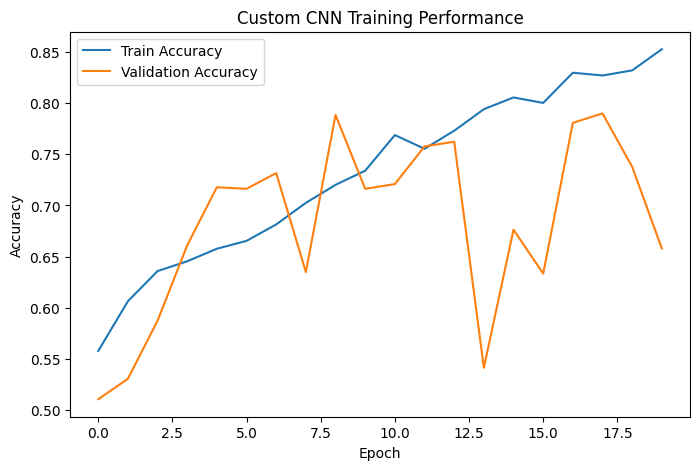

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Custom CNN Training Performance")
plt.show()


In [20]:
MODEL_PATH = "../parkinsons_handwriting_custom_cnn1.keras"
model.save(MODEL_PATH)

print("✅ Model saved as:", MODEL_PATH)


✅ Model saved as: ../parkinsons_handwriting_custom_cnn1.keras
